In [ ]:
"""from huggingface_hub import hf_hub_download
from pathlib import Path
import shutil

# Dataset repository
repo_id = "AkshayKarthick/india-weather-air-quality"

# Destination folder
raw_dir = Path("data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

# Files to download
files = [
    "weather_daily.csv",
    "cities.csv"
]

for filename in files:

    print(f"Downloading {filename}...")

    downloaded_file = hf_hub_download(
        repo_id=repo_id,
        filename=filename,
        repo_type="dataset"
    )

    destination = raw_dir / filename

    shutil.copy2(downloaded_file, destination)

    print(f"Saved to: {destination}")

print("\nDataset download completed!")"""

weather_daily.csv:   0%|          | 0.00/9.03M [00:00<?, ?B/s]

d:\PG Study material\Foundations of AI\LSTM_explainer\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dhanu\.cache\huggingface\hub\datasets--AkshayKarthick--india-weather-air-quality. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Saved to: data\raw\weather_daily.csv


cities.csv:   0%|          | 0.00/2.42k [00:00<?, ?B/s]

Saved to: data\raw\cities.csv

Dataset download completed!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

weather_path = RAW_DIR / "weather_daily.csv"
cities_path = RAW_DIR / "cities.csv"

print("Project Directory:", PROJECT_DIR)
print("Weather File Exists:", weather_path.exists())
print("Cities File Exists:", cities_path.exists())

Project Directory: d:\PG Study material\Foundations of AI\LSTM_explainer
Weather File Exists: True
Cities File Exists: True


In [5]:
weather_df = pd.read_csv(weather_path)
cities_df = pd.read_csv(cities_path)

print("Weather Dataset Loaded!")
print("Cities Dataset Loaded!")

Weather Dataset Loaded!
Cities Dataset Loaded!


In [6]:
print("Weather Dataset Shape:", weather_df.shape)
print("Cities Dataset Shape:", cities_df.shape)

Weather Dataset Shape: (124700, 14)
Cities Dataset Shape: (50, 6)


In [7]:
display(weather_df.head())

display(cities_df.head())

,date,city,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code
0,2020-01-01,Agartala,26.2,16.2,20.5,28.3,0.3,3.0,79,11.5,60,11.62,2.29,51
1,2020-01-02,Agartala,26.5,15.0,20.2,28.8,0.0,0.0,86,8.0,30,11.70,2.25,3
2,2020-01-03,Agartala,20.2,15.7,18.0,21.4,18.5,16.0,90,17.1,27,5.77,1.14,63
3,2020-01-04,Agartala,21.8,14.7,17.9,22.7,0.6,2.0,86,9.4,221,8.38,1.62,51
4,2020-01-05,Agartala,21.8,13.6,17.0,22.1,0.0,0.0,85,8.7,358,9.72,1.82,3


,city,state,region,latitude,longitude,elevation_m
0,Delhi,Delhi,North,28.6139,77.2090,214.0
1,Mumbai,Maharashtra,West,19.0760,72.8777,6.0
2,Kolkata,West Bengal,East,22.5726,88.3639,12.0
3,Chennai,Tamil Nadu,South,13.0827,80.2707,12.0
4,Bengaluru,Karnataka,South,12.9716,77.5946,910.0


In [8]:
print("Weather Columns:")
print(weather_df.columns.tolist())

print("\nCity Columns:")
print(cities_df.columns.tolist())

Weather Columns:
['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']

City Columns:
['city', 'state', 'region', 'latitude', 'longitude', 'elevation_m']


In [9]:
print(weather_df.info())

print("\nCity Metadata Information:")
print(cities_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 124700 entries, 0 to 124699
Data columns (total 14 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   date                         124700 non-null  str    
 1   city                         124700 non-null  str    
 2   temperature_2m_max           124700 non-null  float64
 3   temperature_2m_min           124700 non-null  float64
 4   temperature_2m_mean          124700 non-null  float64
 5   apparent_temperature_max     124700 non-null  float64
 6   precipitation_sum            124700 non-null  float64
 7   precipitation_hours          124700 non-null  float64
 8   relative_humidity_2m_mean    124700 non-null  int64  
 9   wind_speed_10m_max           124700 non-null  float64
 10  wind_direction_10m_dominant  124700 non-null  int64  
 11  shortwave_radiation_sum      124700 non-null  float64
 12  et0_fao_evapotranspiration   124700 non-null  float64
 13  weather_co

In [17]:
# Convert date to datetime
weather_df["date"] = pd.to_datetime(weather_df["date"])

# Merge weather observations with city metadata
full_weather_df = weather_df.merge(
    cities_df,
    on="city",
    how="left"
)

print("Full Dataset Shape:", full_weather_df.shape)

display(full_weather_df.head())

Full Dataset Shape: (124700, 19)


,date,city,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m
0,2020-01-01,Agartala,26.2,16.2,20.5,28.3,0.3,3.0,79,11.5,60,11.62,2.29,51,Tripura,Northeast,23.8315,91.2868,12.0
1,2020-01-02,Agartala,26.5,15.0,20.2,28.8,0.0,0.0,86,8.0,30,11.70,2.25,3,Tripura,Northeast,23.8315,91.2868,12.0
2,2020-01-03,Agartala,20.2,15.7,18.0,21.4,18.5,16.0,90,17.1,27,5.77,1.14,63,Tripura,Northeast,23.8315,91.2868,12.0
3,2020-01-04,Agartala,21.8,14.7,17.9,22.7,0.6,2.0,86,9.4,221,8.38,1.62,51,Tripura,Northeast,23.8315,91.2868,12.0
4,2020-01-05,Agartala,21.8,13.6,17.0,22.1,0.0,0.0,85,8.7,358,9.72,1.82,3,Tripura,Northeast,23.8315,91.2868,12.0


In [18]:
available_states = sorted(
    full_weather_df["state"].dropna().unique()
)

print("Number of available states:", len(available_states))

print("\nAvailable States:")

for state in available_states:
    print(state)

Number of available states: 30

Available States:
Andaman and Nicobar Islands
Andhra Pradesh
Assam
Bihar
Chandigarh
Chhattisgarh
Delhi
Goa
Gujarat
Himachal Pradesh
Jammu and Kashmir
Jharkhand
Karnataka
Kerala
Ladakh
Madhya Pradesh
Maharashtra
Manipur
Meghalaya
Odisha
Puducherry
Punjab
Rajasthan
Sikkim
Tamil Nadu
Telangana
Tripura
Uttar Pradesh
Uttarakhand
West Bengal


In [19]:
state_city_count = (
    cities_df.groupby("state")["city"]
    .nunique()
    .sort_values(ascending=False)
)

display(state_city_count)

state
Uttar Pradesh     5
Maharashtra       4
Madhya Pradesh    3
Tamil Nadu        3
Karnataka         3
                 ..
Sikkim            1
Telangana         1
Tripura           1
Uttarakhand       1
West Bengal       1
Name: city, Length: 30, dtype: int64

In [20]:
state_city_mapping = (
    cities_df.groupby("state")["city"]
    .apply(lambda x: sorted(x.unique()))
    .to_dict()
)

for state, cities in state_city_mapping.items():

    print(f"\n{state}")
    print("Available Cities:", cities)


Andaman and Nicobar Islands
Available Cities: ['Port Blair']

Andhra Pradesh
Available Cities: ['Vijayawada', 'Visakhapatnam']

Assam
Available Cities: ['Guwahati']

Bihar
Available Cities: ['Patna']

Chandigarh
Available Cities: ['Chandigarh']

Chhattisgarh
Available Cities: ['Raipur']

Delhi
Available Cities: ['Delhi']

Goa
Available Cities: ['Panaji']

Gujarat
Available Cities: ['Ahmedabad', 'Surat', 'Vadodara']

Himachal Pradesh
Available Cities: ['Shimla']

Jammu and Kashmir
Available Cities: ['Jammu', 'Srinagar']

Jharkhand
Available Cities: ['Ranchi']

Karnataka
Available Cities: ['Bengaluru', 'Mangaluru', 'Mysuru']

Kerala
Available Cities: ['Kochi', 'Thiruvananthapuram']

Ladakh
Available Cities: ['Leh']

Madhya Pradesh
Available Cities: ['Bhopal', 'Gwalior', 'Indore']

Maharashtra
Available Cities: ['Mumbai', 'Nagpur', 'Nashik', 'Pune']

Manipur
Available Cities: ['Imphal']

Meghalaya
Available Cities: ['Shillong']

Odisha
Available Cities: ['Bhubaneswar']

Puducherry
Availa

In [21]:
print("Merged dataset shape:", full_weather_df.shape)

print(
    "Unmatched city records:",
    full_weather_df["state"].isna().sum()
)

print(
    "Unique cities:",
    full_weather_df["city"].nunique()
)

Merged dataset shape: (124700, 19)
Unmatched city records: 0
Unique cities: 50


In [22]:
missing_values = full_weather_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(full_weather_df)
    ) * 100
})

display(
    missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
date,0,0.0
city,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
temperature_2m_mean,0,0.0
apparent_temperature_max,0,0.0
precipitation_sum,0,0.0
precipitation_hours,0,0.0
relative_humidity_2m_mean,0,0.0
wind_speed_10m_max,0,0.0


In [23]:
duplicates = full_weather_df.duplicated(
    subset=["city", "date"]
).sum()

print("Duplicate city-date records:", duplicates)

Duplicate city-date records: 0


In [24]:
date_summary = []

for city, group in full_weather_df.groupby("city"):

    dates = pd.to_datetime(group["date"])

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="D"
    )

    missing_dates = expected_dates.difference(dates)

    date_summary.append({
        "city": city,
        "start_date": dates.min(),
        "end_date": dates.max(),
        "total_records": len(group),
        "missing_dates": len(missing_dates)
    })

date_summary_df = pd.DataFrame(date_summary)

display(date_summary_df)

,city,start_date,end_date,total_records,missing_dates
0,Agartala,2020-01-01,2026-10-29,2494,0
1,Agra,2020-01-01,2026-10-29,2494,0
2,Ahmedabad,2020-01-01,2026-10-29,2494,0
3,Amritsar,2020-01-01,2026-10-29,2494,0
4,Bengaluru,2020-01-01,2026-10-29,2494,0
...,...,...,...,...,...
45,Thiruvananthapuram,2020-01-01,2026-10-29,2494,0
46,Vadodara,2020-01-01,2026-10-29,2494,0
47,Varanasi,2020-01-01,2026-10-29,2494,0
48,Vijayawada,2020-01-01,2026-10-29,2494,0


In [25]:
display(
    full_weather_df.groupby("state")[
        "temperature_2m_max"
    ].agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ]).round(2)
)

,count,mean,std,min,max
state,,,,,
Andaman and Nicobar Islands,2494,29.91,1.75,25.4,36.2
Andhra Pradesh,4988,32.69,3.44,21.9,44.8
Assam,2494,28.79,3.72,16.0,39.5
Bihar,2494,30.51,5.46,15.3,43.6
Chandigarh,2494,29.03,6.61,12.4,43.9
...,...,...,...,...,...
Telangana,2494,31.14,3.46,20.1,41.4
Tripura,2494,30.28,3.39,20.2,38.6
Uttar Pradesh,12470,31.23,6.32,14.2,47.5


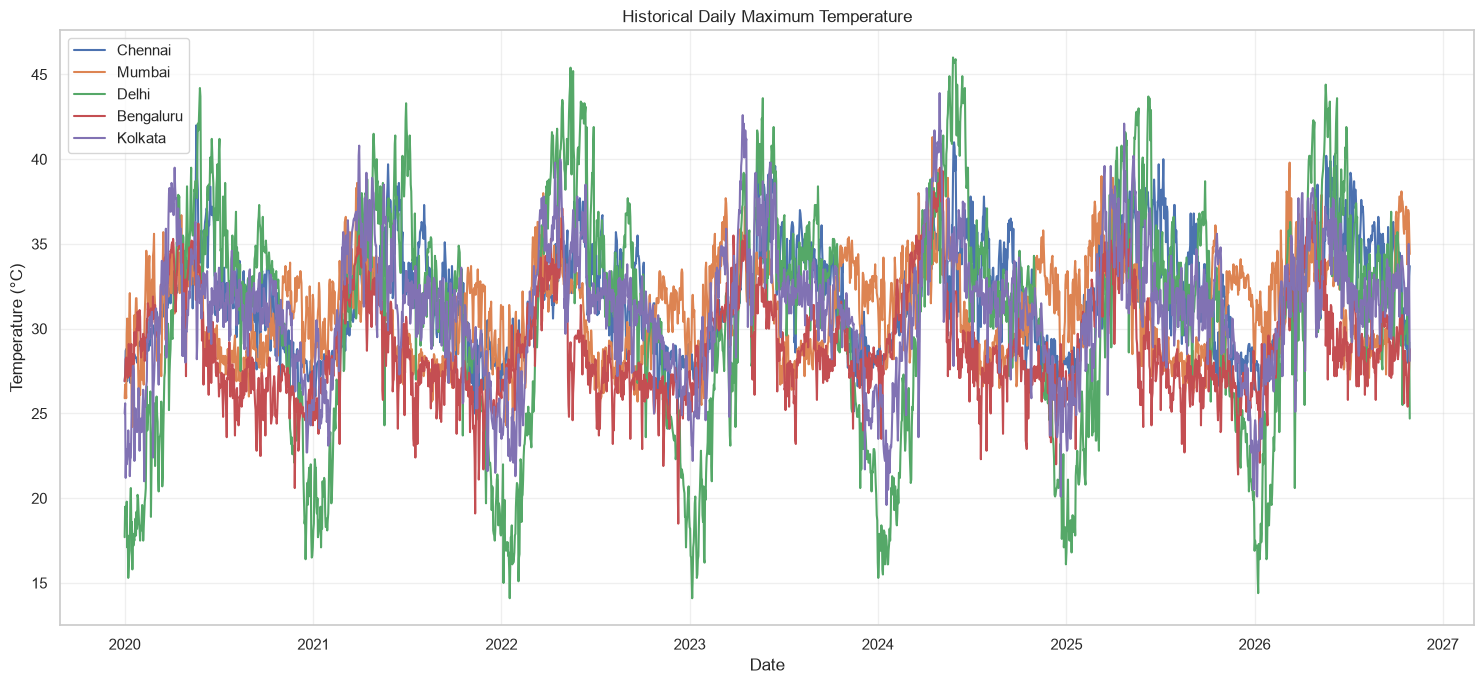

In [26]:
selected_cities = [
    "Chennai",
    "Mumbai",
    "Delhi",
    "Bengaluru",
    "Kolkata"
]

plt.figure(figsize=(15, 7))

for city in selected_cities:

    city_data = full_weather_df[
        full_weather_df["city"] == city
    ]

    plt.plot(
        city_data["date"],
        city_data["temperature_2m_max"],
        label=city
    )

plt.title("Historical Daily Maximum Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Next: Temperature distribution and outlier analysis

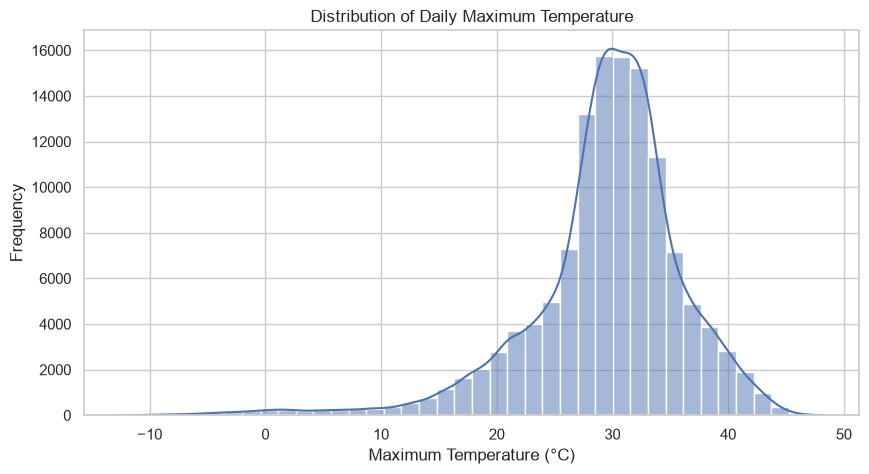

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=full_weather_df,
    x="temperature_2m_max",
    bins=40,
    kde=True
)

plt.title("Distribution of Daily Maximum Temperature")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Frequency")

plt.show()

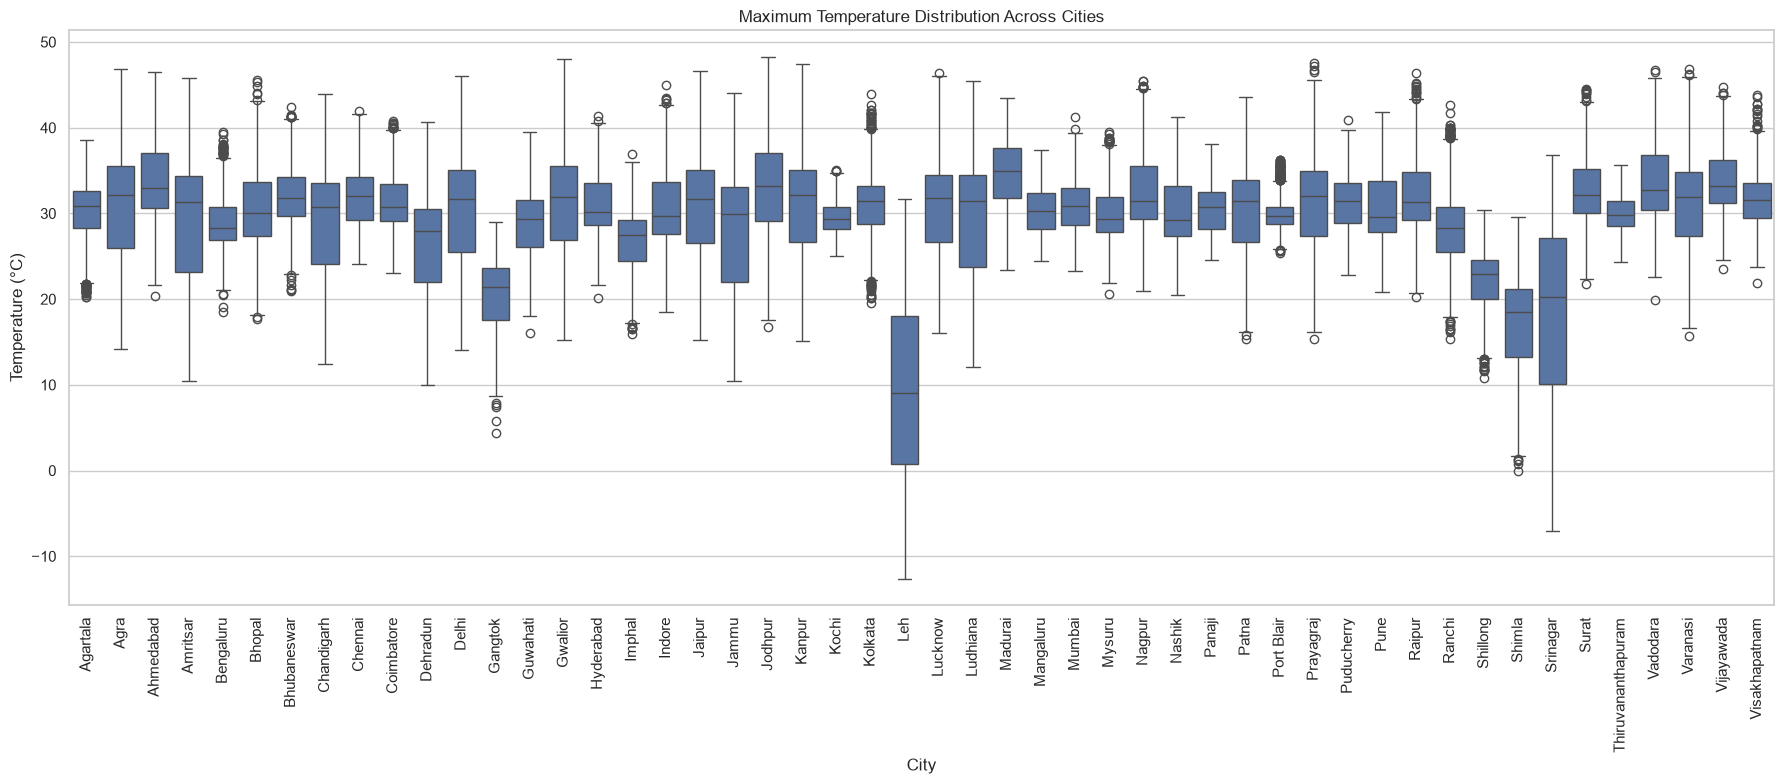

In [28]:
plt.figure(figsize=(18, 8))

sns.boxplot(
    data=full_weather_df,
    x="city",
    y="temperature_2m_max"
)

plt.title("Maximum Temperature Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [29]:
temperature_stats = (
    full_weather_df.groupby("city")["temperature_2m_max"]
    .agg(["min", "max", "mean", "std"])
    .round(2)
)

display(
    temperature_stats.sort_values(
        "max",
        ascending=False
    )
)

,min,max,mean,std
city,,,,
Jodhpur,16.7,48.3,32.84,5.64
Gwalior,15.2,48.0,31.40,6.44
Prayagraj,15.3,47.5,31.49,6.16
Kanpur,15.1,47.4,31.25,6.39
Agra,14.2,46.9,31.13,6.78
...,...,...,...,...
Kochi,25.0,35.1,29.57,1.80
Leh,-12.6,31.7,9.34,10.03
Shillong,10.8,30.4,22.13,3.32


In [31]:
from IPython.display import display

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 200
):
    display(temperature_stats)

,min,max,mean,std
city,,,,
Agartala,20.2,38.6,30.28,3.39
Agra,14.2,46.9,31.13,6.78
Ahmedabad,20.4,46.5,33.79,4.70
Amritsar,10.4,45.8,29.30,7.45
Bengaluru,18.5,39.5,28.95,3.02
Bhopal,17.7,45.6,30.81,5.15
Bhubaneswar,21.0,42.4,31.96,3.55
Chandigarh,12.4,43.9,29.03,6.61
Chennai,24.1,42.0,31.95,3.16


In [30]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

full_weather_df.to_csv(
    PROCESSED_DIR / "india_weather_merged.csv",
    index=False
)

print("Merged dataset saved successfully!")

Merged dataset saved successfully!


In [32]:
full_weather_df["month"] = (
    full_weather_df["date"].dt.month
)

In [33]:
monthly_temp = (
    full_weather_df.groupby(
        ["city", "month"]
    )["temperature_2m_max"]
    .mean()
    .reset_index()
)

display(monthly_temp.head(15))

,city,month,temperature_2m_max
0,Agartala,1,24.611982
1,Agartala,2,27.491919
2,Agartala,3,31.685253
3,Agartala,4,33.684762
4,Agartala,5,32.626267
5,Agartala,6,31.623810
6,Agartala,7,31.586636
7,Agartala,8,31.345161
8,Agartala,9,31.890476
9,Agartala,10,31.246977


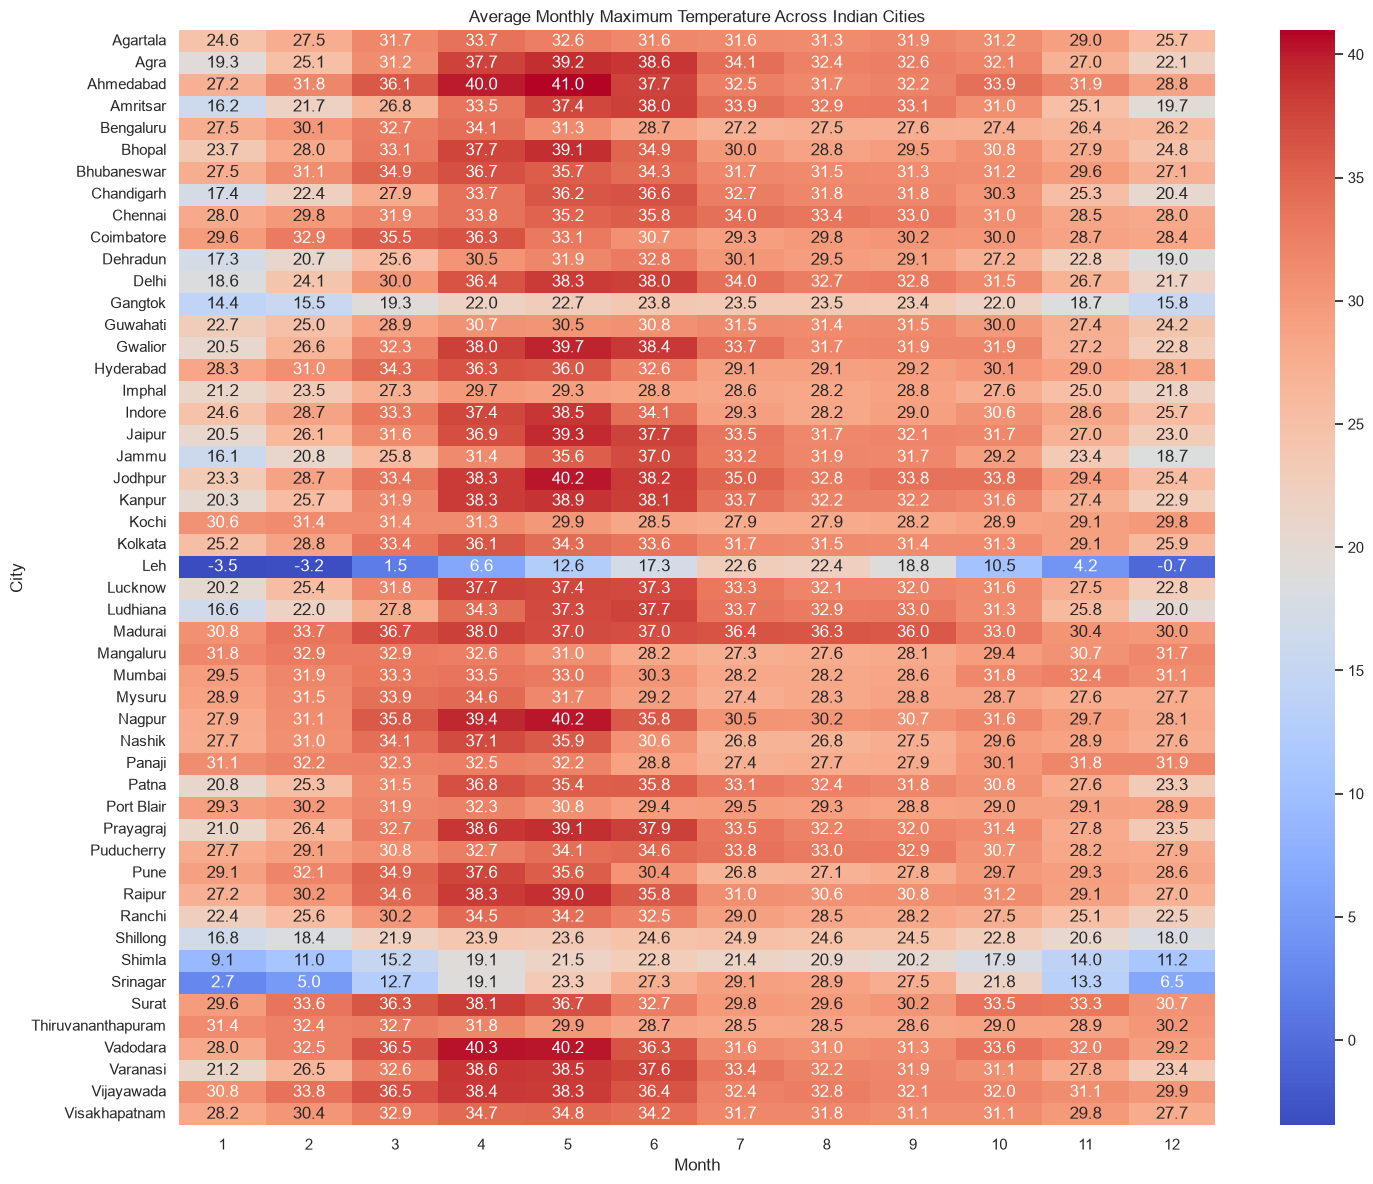

In [34]:
monthly_pivot = monthly_temp.pivot(
    index="city",
    columns="month",
    values="temperature_2m_max"
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    monthly_pivot,
    cmap="coolwarm",
    annot=True,
    fmt=".1f"
)

plt.title("Average Monthly Maximum Temperature Across Indian Cities")
plt.xlabel("Month")
plt.ylabel("City")

plt.tight_layout()
plt.show()